# Jump model vs *binary* rules (like-for-like), pre-registered, final

**Why this exists.** `regime-jump-model.ipynb` compared a binary in/out model with *continuous* vol-targeting, which are different kinds of rule. The one claim the jump model (SJM) kept standing was **drawdown control with long-lived regimes**. The like-for-like benchmark is a simple *binary* rule. A 200-day moving average and a VIX hysteresis rule were on the original benchmark list and were omitted in the last round (my omission).

**This round is not blind:** the SJM numbers were already seen. To limit forking paths, the benchmarks and the decision rule are fixed here from convention, with **no tuning**, and this is the last test on the SJM.

## Fixed design
* **SJM:** identical to the previous notebook (same code, seed, features, lambda rule, walk-forward, 10 bps, 2-day execution delay). It is deterministic, so the signals must reproduce the previous results; a reproducibility check is printed.
* **Binary benchmarks** (same delay, same costs, same cash rate, same OOS days):
  1. **200-day MA:** invested if `close > SMA(200)`, else cash.
  2. **VIX hysteresis:** to cash when VIX exceeds its trailing-756-day 80th percentile, back in when below the 60th percentile, otherwise hold the previous state (percentiles are causal and market-agnostic, so no India-vs-US level is hard-coded).
* **Markets:** Nifty (primary), S&P 500 (second primary for this question; both must pass).

## Kill rule
The SJM's drawdown-control claim is **retained only if, on BOTH markets and against EACH of the two binary rules**:
* **(D1)** Calmar(SJM) > Calmar(rule), with paired moving-block-bootstrap (20-day blocks, 2,000 draws) **P(diff <= 0) < 0.10**; and
* **(D2)** the SJM's max drawdown is **not deeper** than the rule's.

Anything else -> the SJM has **no remaining demonstrated utility** over simple binary rules and the matter is settled. Turnover, Sharpe, average exposure and sub-period results are **descriptive** (turnover is shown because "matches drawdown *and* turnover" is the substantive concern, but it is not part of the formal rule).


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import regime_filter as rf, jump_model as jm, regime_allocation as ra

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
COST = 10.0
PRIOR = {"Nifty": {"Sharpe": 0.453, "MaxDD": -0.158}, "S&P 500": {"Sharpe": 0.445, "MaxDD": -0.218}}  # from regime-jump-model.ipynb

def run_binary(df, rf_annual, label):
    feats = rf.build_features(df); idx = feats.index
    ret_full = df["close"].pct_change(); ret = ret_full.reindex(idx)
    X = jm.sjm_features(ret_full, rf_annual).reindex(idx)
    J = jm.jm_walk_forward(X, ret, jm.JMConfig(rf_annual=rf_annual, cost_bps=COST))
    expo = {
        "SJM (0/1)": J["bull"],
        "200d MA": jm.ma_exposure(df["close"]).reindex(J["bull"].index),
        "VIX hysteresis": jm.vix_hysteresis_exposure(df["vix"]).reindex(J["bull"].index),
        "Buy & hold": pd.Series(1.0, index=J["bull"].index),
    }
    rets = {k: rf.backtest(ret.reindex(J["bull"].index), v.shift(1), rf_annual, COST).dropna() for k, v in expo.items()}
    common = rets["SJM (0/1)"].index
    for k in rets: common = common.intersection(rets[k].index)
    rets = {k: v.loc[common] for k, v in rets.items()}
    tab = pd.DataFrame({k: rf.perf(rets[k], expo[k], rf_annual) for k in rets})
    sw = {k: int((expo[k].reindex(common).diff().abs() > 0).sum()) for k in expo}
    tab.loc["Switches/yr"] = pd.Series({k: v / (len(common) / rf.TRADING_DAYS) for k, v in sw.items()})
    print(f"[{label}] OOS {common.min().date()} -> {common.max().date()} ({len(common)} days)")
    return dict(tab=tab, rets=rets, expo=expo, rf_annual=rf_annual, J=J)

def verdict(R, label):
    rets, tab = R["rets"], R["tab"]
    prior = PRIOR[label]
    print(f"[{label}] reproducibility: SJM Sharpe {tab.loc['Sharpe','SJM (0/1)']:.3f} (previous {prior['Sharpe']}), MaxDD {tab.loc['MaxDD','SJM (0/1)']:.3f} (previous {prior['MaxDD']})")
    res = {}
    for b in ["200d MA", "VIX hysteresis"]:
        pt, lo, hi, p = jm.block_bootstrap_calmar_diff(rets["SJM (0/1)"], rets[b])
        d1 = pt > 0 and p < 0.10
        d2 = tab.loc["MaxDD", "SJM (0/1)"] >= tab.loc["MaxDD", b]   # MaxDD is negative: >= means not deeper
        res[b] = (d1, d2)
        print(f"[{label}] vs {b}: dCalmar={pt:+.3f} (95% CI {lo:+.3f}..{hi:+.3f}), P(diff<=0)={p:.3f} -> D1 {'PASS' if d1 else 'FAIL'};"
              f"  MaxDD SJM {tab.loc['MaxDD','SJM (0/1)']:.3f} vs {tab.loc['MaxDD', b]:.3f} -> D2 {'PASS' if d2 else 'FAIL'}")
    return all(a and b for a, b in res.values())

## 1. Nifty 50 + India VIX

In [2]:
px = ra.download_assets()
nifty = pd.DataFrame({"close": px["nifty"], "vix": px["vix"]})
RN = run_binary(nifty, 0.06, "Nifty")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RN["tab"]

[Nifty] OOS 2013-03-21 -> 2026-10-16 (3292 days)


,SJM (0/1),200d MA,VIX hysteresis,Buy & hold
CAGR,0.100,0.073,0.054,0.113
AnnVol,0.092,0.116,0.112,0.163
Sharpe,0.453,0.165,0.002,0.383
Sortino,0.637,0.228,0.003,0.526
MaxDD,-0.158,-0.232,-0.252,-0.384
Calmar,0.637,0.315,0.213,0.295
AvgExposure,0.521,0.751,0.753,1.000
AnnTurnover,2.527,8.959,3.216,0.000
Switches/yr,2.526,8.956,3.215,0.000


In [3]:
ok_n = verdict(RN, "Nifty")

[Nifty] reproducibility: SJM Sharpe 0.453 (previous 0.453), MaxDD -0.158 (previous -0.158)


[Nifty] vs 200d MA: dCalmar=+0.322 (95% CI -0.046..+1.024), P(diff<=0)=0.040 -> D1 PASS;  MaxDD SJM -0.158 vs -0.232 -> D2 PASS


[Nifty] vs VIX hysteresis: dCalmar=+0.424 (95% CI +0.050..+1.191), P(diff<=0)=0.014 -> D1 PASS;  MaxDD SJM -0.158 vs -0.252 -> D2 PASS


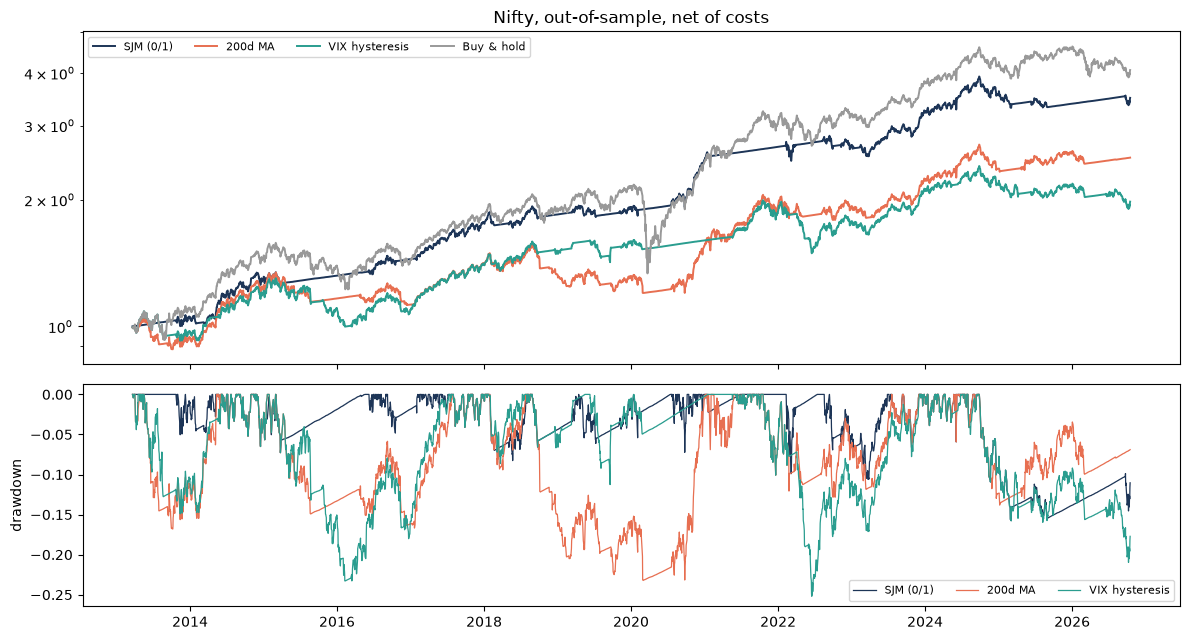

In [4]:
rets = RN["rets"]
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
pal = {"SJM (0/1)": "#1d3557", "200d MA": "#e76f51", "VIX hysteresis": "#2a9d8f", "Buy & hold": "#999999"}
for k, r in rets.items():
    eq = (1 + r).cumprod(); ax[0].plot(eq, label=k, color=pal[k], lw=1.4)
    if k != "Buy & hold": ax[1].plot(eq / eq.cummax() - 1, color=pal[k], lw=0.9, label=k)
ax[0].set_yscale("log"); ax[0].legend(ncol=4, fontsize=8); ax[0].set_title("Nifty, out-of-sample, net of costs"); ax[1].set_ylabel("drawdown"); ax[1].legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

## 2. S&P 500 + VIX

In [5]:
sp = pd.read_csv("sp500_vix.csv", index_col=0, parse_dates=True)
RS = run_binary(sp, 0.02, "S&P 500")
display(RS["tab"])
ok_s = verdict(RS, "S&P 500")

[S&P 500] OOS 2004-02-11 -> 2026-10-19 (5708 days)


,SJM (0/1),200d MA,VIX hysteresis,Buy & hold
CAGR,0.067,0.061,0.049,0.088
AnnVol,0.115,0.113,0.106,0.187
Sharpe,0.445,0.407,0.318,0.437
Sortino,0.604,0.552,0.431,0.611
MaxDD,-0.218,-0.232,-0.226,-0.568
Calmar,0.306,0.264,0.217,0.154
AvgExposure,0.756,0.783,0.707,1.000
AnnTurnover,1.501,6.977,4.283,0.000
Switches/yr,1.501,6.975,4.282,0.000


[S&P 500] reproducibility: SJM Sharpe 0.445 (previous 0.445), MaxDD -0.218 (previous -0.218)


[S&P 500] vs 200d MA: dCalmar=+0.042 (95% CI -0.189..+0.249), P(diff<=0)=0.429 -> D1 FAIL;  MaxDD SJM -0.218 vs -0.232 -> D2 PASS


[S&P 500] vs VIX hysteresis: dCalmar=+0.089 (95% CI -0.137..+0.327), P(diff<=0)=0.218 -> D1 FAIL;  MaxDD SJM -0.218 vs -0.226 -> D2 PASS


In [6]:
print("=" * 72)
if ok_n and ok_s:
    final = "RETAINED: SJM beats BOTH binary rules on drawdown-adjusted performance on both markets."
else:
    final = "SETTLED: SJM shows no demonstrated utility over simple binary rules (fails the pre-registered D1/D2 conditions)."
print("FINAL VERDICT:", final)

FINAL VERDICT: SETTLED: SJM shows no demonstrated utility over simple binary rules (fails the pre-registered D1/D2 conditions).


## Conclusions (final)

**Verdict under the pre-registered rule: SETTLED, no demonstrated utility over simple binary rules.** The rule required D1 (Calmar advantage, bootstrap P < 0.10) and D2 (drawdown not deeper) against both rules on **both** markets; it fails on the S&P.

| | Nifty: SJM | 200d MA | VIX hyst. | | S&P: SJM | 200d MA | VIX hyst. |
|---|---|---|---|---|---|---|---|
| Max drawdown | **-15.8%** | -23.2% | -25.2% | | **-21.8%** | -23.2% | -22.6% |
| Calmar | **0.64** | 0.32 | 0.21 | | **0.31** | 0.26 | 0.22 |
| Sharpe | 0.45 | 0.17 | 0.00 | | 0.45 | 0.41 | 0.32 |
| Switches / year | **2.5** | 9.0 | 3.2 | | **1.5** | 7.0 | 4.3 |

* **Nifty:** the SJM beats both binary rules on Calmar (dCalmar +0.32 and +0.42; P(diff <= 0) = 0.040 and 0.014) with a shallower drawdown. D1 and D2 pass.
* **S&P 500:** the SJM's drawdown is only 1.4 and 0.8 points shallower, and the Calmar edge is statistically indistinguishable from zero (dCalmar +0.04 and +0.09; P = 0.43 and 0.22). D1 fails. A 200-day MA essentially **matches the SJM's drawdown** there.
* **Not part of the formal rule, but relevant:** on both markets the SJM trades far less (1.5 to 2.5 switches a year against 7 to 9 for the 200-day MA), and results are already net of 10 bps. So "a 200-day MA matches drawdown **and** turnover" is **not** quite true: it matches drawdown on the S&P but needs ~4.6x more switching.
* This is the third look at the SJM, so the Nifty p-values (0.04, 0.014) deserve a multiple-testing discount, and the signals reproduced the previous run exactly (Sharpe 0.453 / 0.445, max drawdown -15.8% / -21.8%).

**Bottom line:** the jump model gives the same or better drawdown control than a 200-day MA or a VIX rule with far fewer trades, strongly on Nifty and marginally on the S&P, but the pre-registered bar (both markets) is not met. As agreed, no further variants.
